# Plotting and serialization

:::{note} R binding
The R package supports `plot_risk`, `plot_varimp`, `plot_selected`,
`plot_residuals`, `plot_coef_path`, `plot_diagnostics`, `plot_aic`,
`plot_confint`, `plot_distribution_density`, `plot_centile_fan`, and
`plot_deviance_profile`. Use the Python binding for `plot_partial_effects`,
`plot_cvrisk`, `plot_lss`, `plot_lss_risk`, `plot_multinomial`, and
`plot_stabsel` (16 Python plot types total).
:::

mboostrs uses Altair for all built-in plots. Every plotting function
returns an `alt.Chart` (or `alt.LayerChart`, `alt.ConcatChart`, etc.) so you
can compose, layer, and export figures using the Altair/Vega-Lite ecosystem.

Importing `mboostrs.plot` registers and enables an `mboostrs` Altair theme:
a Tableau 10 color palette, DM Sans (Google Fonts) for titles and
labels, and CommitMono (Eigil Nikolajsen) for tick numerals. The fonts (SIL OFL 1.1)
are bundled with the package and registered with vl-convert, so static export
(`chart.save("fig.png")` / `.svg`) renders identically on any machine — no
font installation needed. Charts embed with the SVG renderer, so in notebooks
and on this site the labels pick up the typeface as soon as the webfont loads
(this book serves the faces via `@font-face`); systems without DM Sans fall
back through the CSS font stack. For a custom chart, pass `list(mboostrs.plot.PALETTE)`
to an Altair categorical scale, or register `mboostrs.plot.theme` as a project theme factory
and adapt its returned configuration. To switch back to Altair's default look,
call `alt.theme.enable("default")`.

In [1]:
import numpy as np
import mboostrs as mb

rng = np.random.default_rng(0)
n = 400
x1 = rng.uniform(-3, 3, n); x2 = rng.normal(size=n)
y = np.sin(x1) + 0.7 * x2 + rng.normal(scale=0.4, size=n)
data = {"x1": x1, "x2": x2, "y": y}
fit = mb.gamboost("y ~ bbs(x1, df=4) + bols(x2)", data=data,
                   family=mb.Gaussian(), control=mb.boost_control(300, 0.1))

## Plot types

| Plot type | Description | When to use |
|---|---|---|
| `plot_risk()` | In-bag empirical risk vs. boosting iteration | Quick check that the model is converging and a rough guide to `mstop` |
| `plot_selected()` | Selection frequency bar chart per base-learner | See which learners are selected most often |
| `plot_varimp()` | Horizontal bar chart of risk reduction per learner | Compare variable importance across the full set of predictors |
| `plot_partial_effects()` | Additive component curves (smooth or linear) | Understand the shape and magnitude of each term's contribution |
| `plot_residuals()` | Working residuals vs. fitted values | Check for heteroskedasticity, nonlinearity, or outliers |
| `plot_confint()` | Bootstrap confidence bands (GAM) or coefficient forest plot (GLM) | Quantify uncertainty around partial effects or coefficient estimates |
| `plot_lss()` | Per-parameter partial effects (GAMLSS) | Inspect how each predictor shifts the location, scale, and shape parameters |
| `plot_distribution_density()` | Observed distribution against the average fitted conditional distribution | Find marginal density or mass mismatch without collapsing varying parameters |
| `plot_centile_fan()` | Nested row-specific predictive centiles against a covariate | Inspect changes in conditional location, spread, skewness, and tails |
| `plot_deviance_profile()` | Mean and upper-tail joint deviance by covariate bin | Locate regions where the fitted distribution performs poorly |
| `plot_multinomial()` | Per-class probability curves over a predictor | Visualize how class probabilities change with a covariate |

## Risk path

`plot_risk` draws the in-bag risk (empirical risk on the training set) against
the boosting iteration. The in-bag risk often decreases and then flattens as `mstop` increases.
Cross-validated risk provides a held-out estimate for choosing `mstop`.

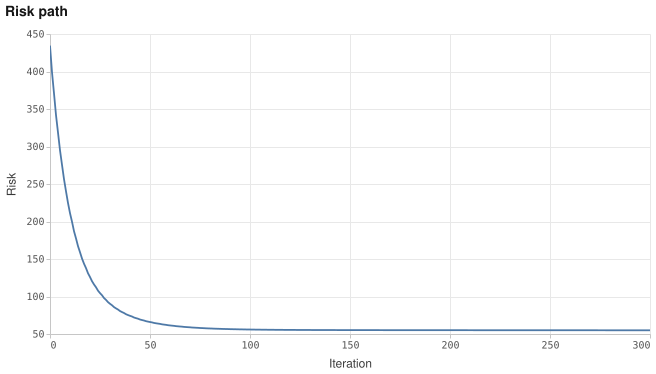

In [2]:
fit.plot_risk()

### Composing charts: alt.hconcat and alt.vconcat

Every plot function returns an Altair chart. Use `alt.hconcat` or `alt.vconcat`
to compose multiple charts side-by-side:

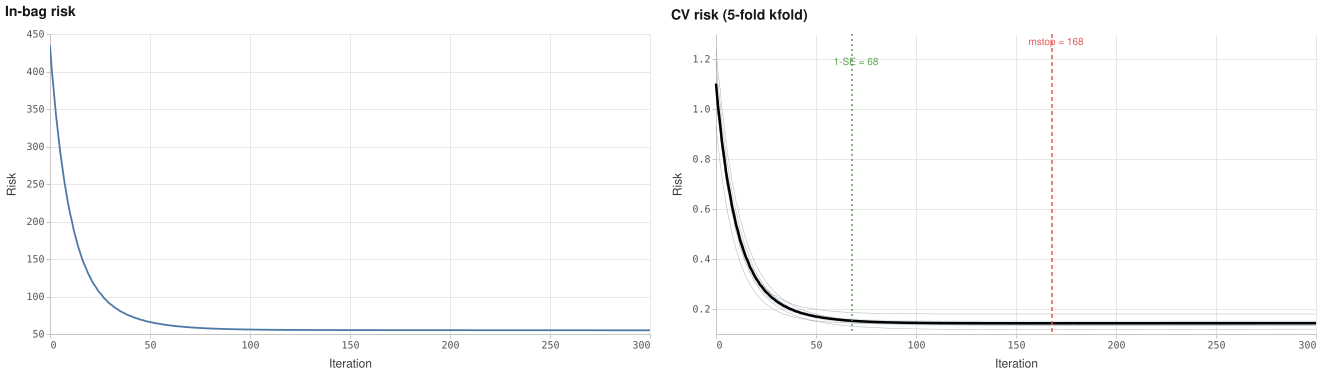

In [3]:
import altair as alt

cvr = fit.cvrisk(type="kfold", B=5, seed=1)
alt.hconcat(fit.plot_risk().properties(title="In-bag risk"),
            mb.plot.plot_cvrisk(cvr))

## Cross-validated risk

`plot_cvrisk` shows every fold's risk path in light gray, the aggregate
cross-validated risk in black, and a vertical line at the optimal `mstop`:

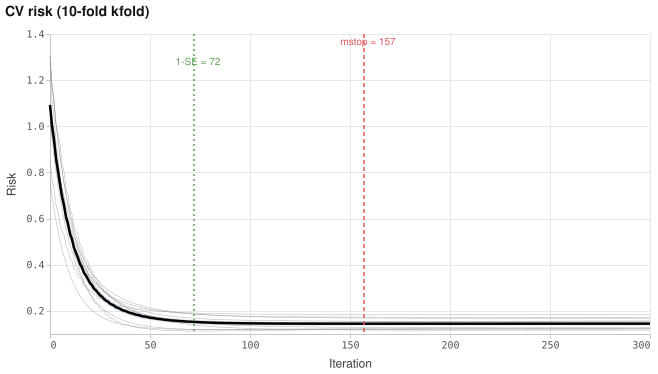

In [4]:
cvr = fit.cvrisk(type="kfold", B=10, seed=42)
mb.plot.plot_cvrisk(cvr)

The optimal stopping iteration is obtained via the `.optimal_mstop` property:

In [5]:
cvr.optimal_mstop

157

See [](model_selection.ipynb) for resampling options (`bootstrap`, `kfold`,
`subsampling`) and theoretical background.

## Partial effects

`plot_partial_effects` evaluates each selected base-learner's contribution to
the additive predictor. For smooth terms (`bbs`, `bmono`), it evaluates on an
equispaced grid; for linear terms (`bols`) it evaluates on the training data.

Call it as a method on the fitted model:

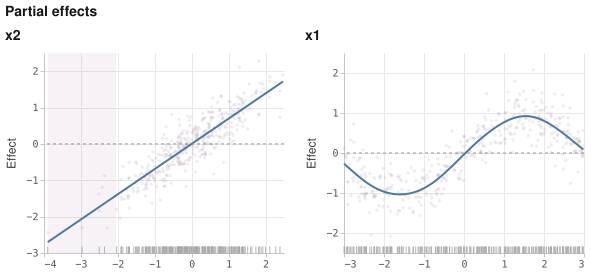

In [6]:
fit.plot_partial_effects()

With multiple effects, the function produces a grid of subplots automatically.
To plot a single effect, pass `which`:

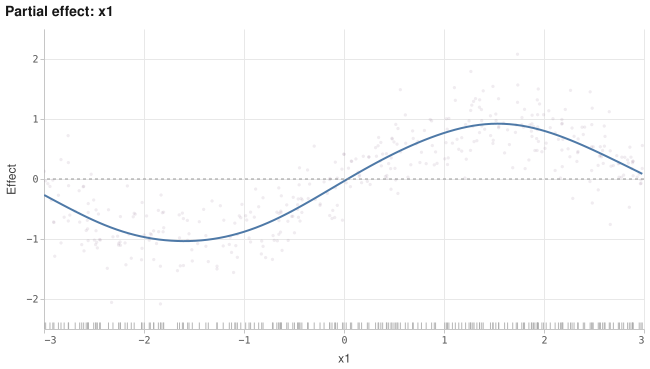

In [7]:
fit.plot_partial_effects(which="x1")

Or compose into a side-by-side layout:

/Users/fcela/src/public_github/mboostrs/.venv/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3748: UserWarning: Automatically deduplicated selection parameter with identical configuration. If you want independent parameters, explicitly name them differently (e.g., name='param1', name='param2'). See https://github.com/vega/altair/issues/3891
  exec(code_obj, self.user_global_ns, self.user_ns)


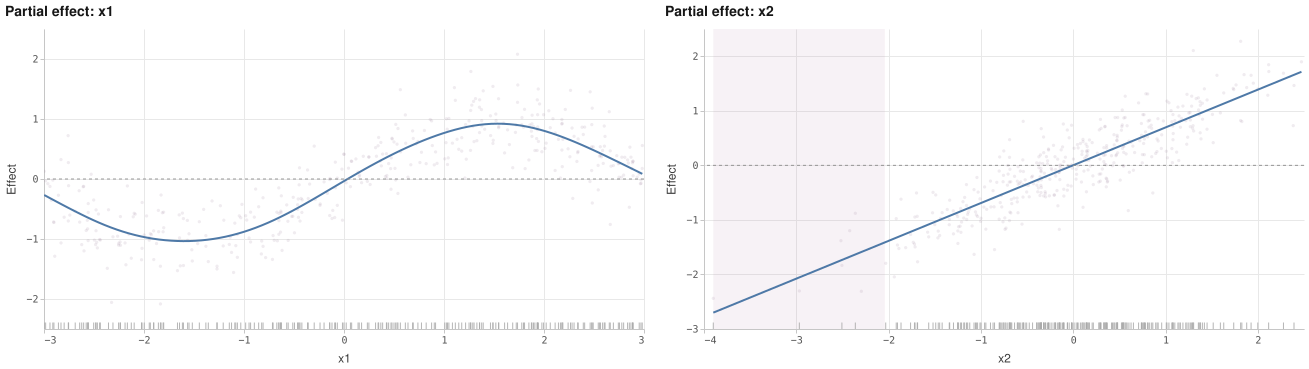

In [8]:
import altair as alt
alt.hconcat(
    fit.plot_partial_effects(which="x1"),
    fit.plot_partial_effects(which="x2"),
)

`fit.plot()` is a shortcut for the same thing.

### Partial effects on new data

`GAMBoostModel.partial_effects()` accepts `newdata` and `n_points`. Use
`newdata` to evaluate effects on a different dataset (e.g. a held-out test
set), and `n_points` to control the smoothness of the evaluation grid:

In [9]:
eff = fit.partial_effects(which="x1", n_points=200)
x_vals, y_vals = eff["x1"]
print(f"{len(x_vals)} grid points from {x_vals.min():.2f} to {x_vals.max():.2f}")
print(f"effect spans {y_vals.min():.3f} to {y_vals.max():.3f}")


200 grid points from -3.00 to 2.98
effect spans -1.035 to 0.922


## Coefficient paths

For GLMBoostModel, `plot_coef_path` shows how each predictor's
cumulative coefficient evolves over boosting iterations. A Lasso path plots
coefficients against a decreasing penalty; this plot has iterations in place of
the penalty:

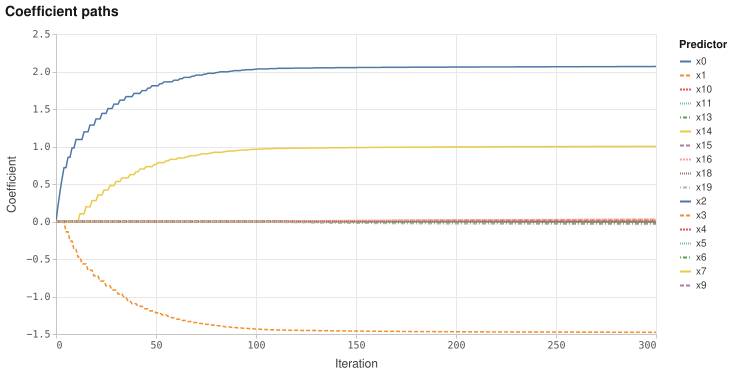

In [10]:
rng2 = np.random.default_rng(1)
n, p = 200, 20
X = rng2.normal(size=(n, p))
beta = np.zeros(p); beta[[0, 3, 7]] = [2.0, -1.5, 1.0]
y2 = X @ beta + rng2.normal(scale=0.5, size=n)
data2 = {f"x{j}": X[:, j] for j in range(p)}; data2["y"] = y2

glm = mb.glmboost("y ~ " + " + ".join(f"x{j}" for j in range(p)),
                   data=data2, family=mb.Gaussian(),
                   control=mb.boost_control(300, 0.1))
glm.plot_coef_path()

Only non-zero predictors are shown by default. Use `which` to select specific
terms:

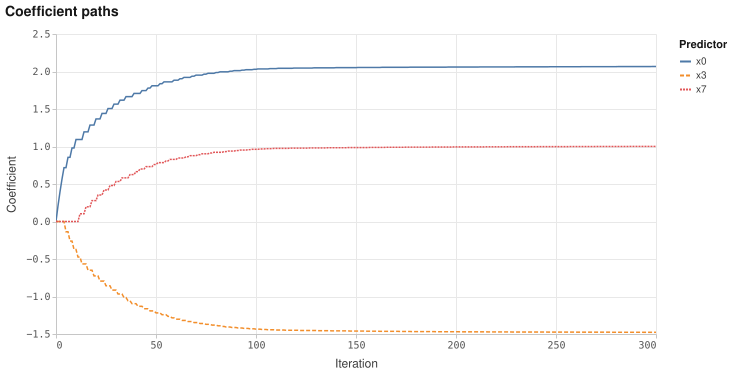

In [11]:
glm.plot_coef_path(which=["x0", "x3", "x7"])

`glm.plot()` is a shortcut for the same thing.

## Variable importance

`plot_varimp` shows a horizontal bar chart of risk reduction per base-learner:

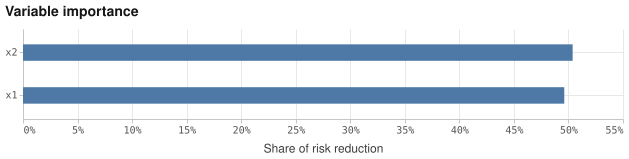

In [12]:
fit.plot_varimp()

The same method works on GLMBoostModel:

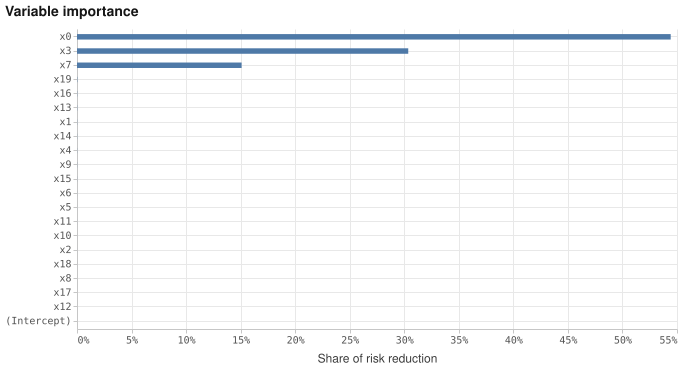

In [13]:
glm.plot_varimp()

The underlying data is available from `fit.varimp()`, which returns a dict
with keys `reduction` (risk reduction percentages) and `selfreq` (selection
frequencies).

## AIC path

Both `GLMBoostModel.aic()` and `GAMBoostModel.aic()` return an `AicResult`
with `.aic` (array), `.mstop` (optimal iteration), and `.df`
(degrees-of-freedom trace). `plot_aic` draws the AIC path with a vertical line
at the optimum:

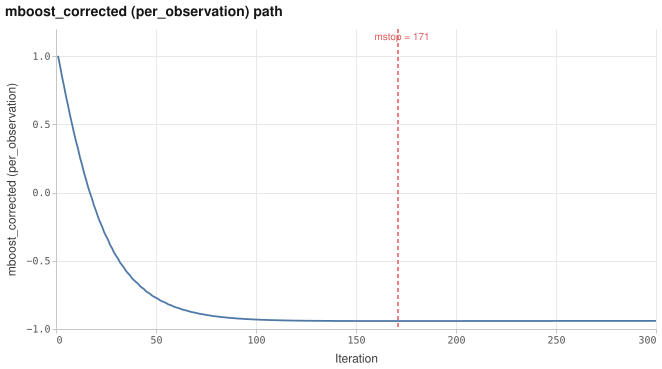

In [14]:
aic = fit.aic()
mb.plot.plot_aic(aic)

See [](model_selection.ipynb) for when to prefer AIC over cross-validated risk.

## Confidence intervals

`plot_confint` runs a bootstrap and overlays confidence bands on the partial
effects (GAMBoostModel) or shows coefficient forest plots (GLMBoostModel):

/Users/fcela/src/public_github/mboostrs/python/mboostrs/plot.py:1702: UserWarning: Bootstrap intervals on a boosted fit under-cover (74% empirical coverage at nominal 90% on the book's additive benchmark): resampling reproduces the shrinkage that early stopping induces instead of correcting it. For calibrated bands, use confint(method='refit'), which refits the selected terms by REML (see mboostrs.selection.gam_refit).
  ci = model.confint(parm=parm, level=level, B=B, seed=seed, newdata=grid)


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 295 is within 5% of the search cap 300; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 300 is within 5% of the search cap 300; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 297 is within 5% of the search cap 300; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 299 is within 5% of the search cap 300; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


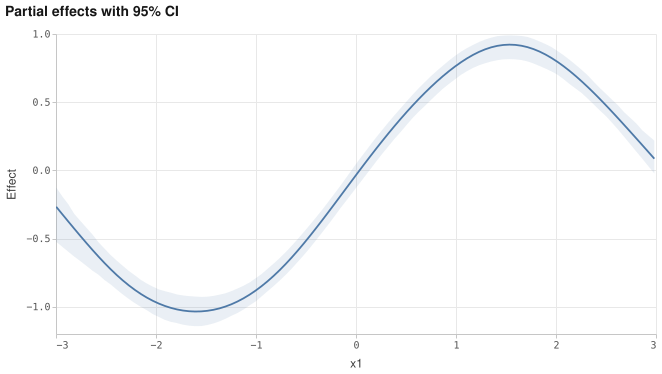

In [15]:
mb.plot.plot_confint(fit, parm="x1", B=200, seed=42)

For GLMBoostModel, the result is a forest plot of coefficients with CI bars:

/Users/fcela/src/public_github/mboostrs/python/mboostrs/plot.py:1601: UserWarning: Bootstrap intervals for boosted coefficients can under-cover: shrinkage and selection bias remain in the replicated fits. For gamboost fits, confint(method='refit') provides conditional REML-refit partial-effect intervals.
  ci = model.confint(parm=parm, level=level, B=B, seed=seed)


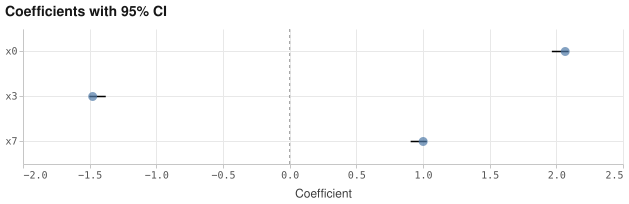

In [16]:
mb.plot.plot_confint(glm, parm=["x0", "x3", "x7"], B=200, seed=42)

## Residuals

`plot_residuals` shows working residuals (response minus fitted) against
fitted values:

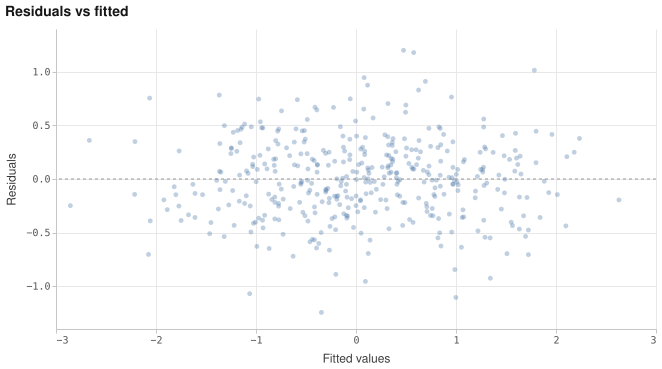

In [17]:
fit.plot_residuals()

Both GLMBoostModel and GAMBoostModel support this.

## Selection frequency

`plot_selected` shows a bar chart of how often each base-learner was selected
over the boosting iterations:

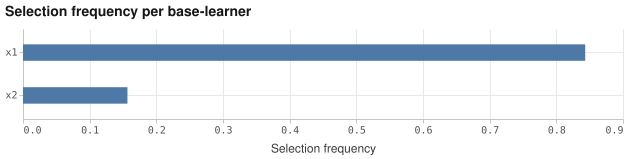

In [18]:
fit.plot_selected()

Both model classes support this.

## LSS models

For `LSSModel` (gamboostLSS / glmboostLSS), `plot_lss_risk` draws the
combined risk path, and `plot_lss` shows the partial effects of each parameter's
linear predictor:

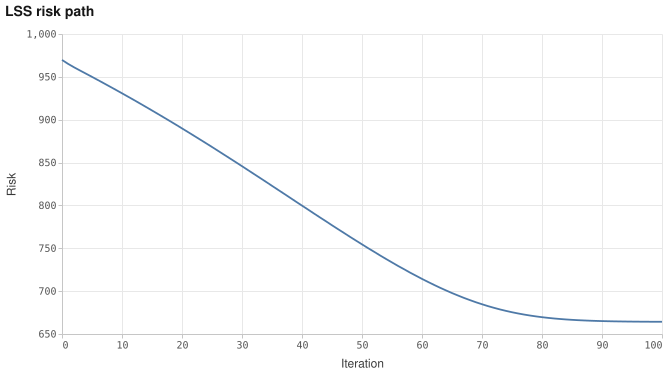

In [19]:
from mboostrs.gamlss import glmboostLSS, GaussianLSS

n3 = 400
xa = rng.uniform(-2, 2, n3)
mu_true = 1.0 + 2.0 * xa
sigma_true = np.exp(0.2 + 0.4 * xa)
ya = mu_true + sigma_true * rng.normal(size=n3)

lss = glmboostLSS("y ~ x", data={"y": ya, "x": xa},
                   family=GaussianLSS(),
                   control=mb.boost_control(100, 0.1))
mb.plot.plot_lss_risk(lss)

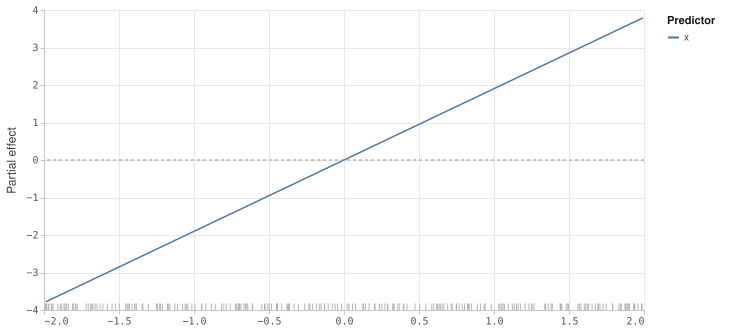

In [20]:
mb.plot.plot_lss(lss, parameter="mu")

## Multinomial models

For Multinomial family models, `plot_multinomial` shows per-class probability
curves:

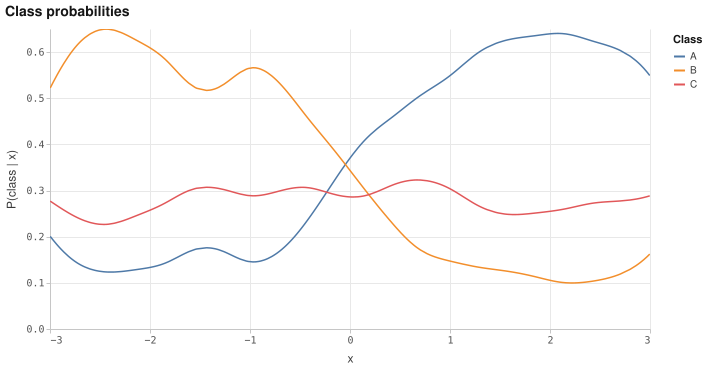

In [21]:
n4 = 400
xm = rng.uniform(-3, 3, n4)
eta = np.column_stack([np.sin(xm), -0.5 * xm])
p = np.exp(np.column_stack([eta, np.zeros(n4)]))
p /= p.sum(1, keepdims=True)
ym = np.array(["A", "B", "C"])[np.array([rng.choice(3, p=pi) for pi in p])]
mm = mb.gamboost("y ~ bbs(x, df=4)", data={"x": xm, "y": ym},
                  family=mb.Multinomial(n_classes=3),
                  control=mb.boost_control(300, 0.1))
mb.plot.plot_multinomial(mm)

## Stability selection

`plot_stabsel` shows a horizontal bar chart of selection probabilities from
`stabsel()`. Bars exceeding the cutoff are colored; those below are grey.

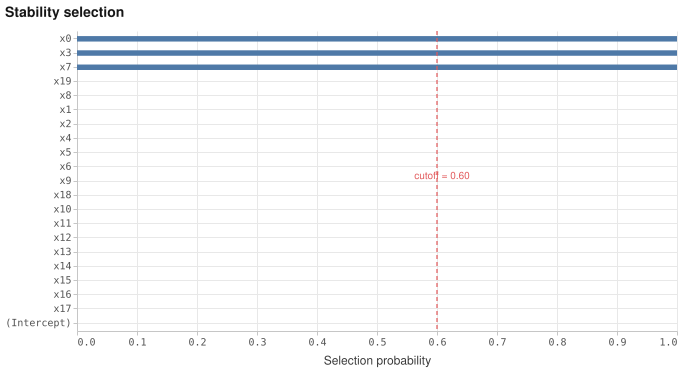

In [22]:
ss = mb.stabsel(glm, cutoff=0.6, q=3)
mb.plot.plot_stabsel(ss)

## Diagnostic dashboard

`plot_diagnostics` produces a 2×2 grid with risk path, selection frequencies,
fitted values, and a residual histogram, as a first check of the fit.

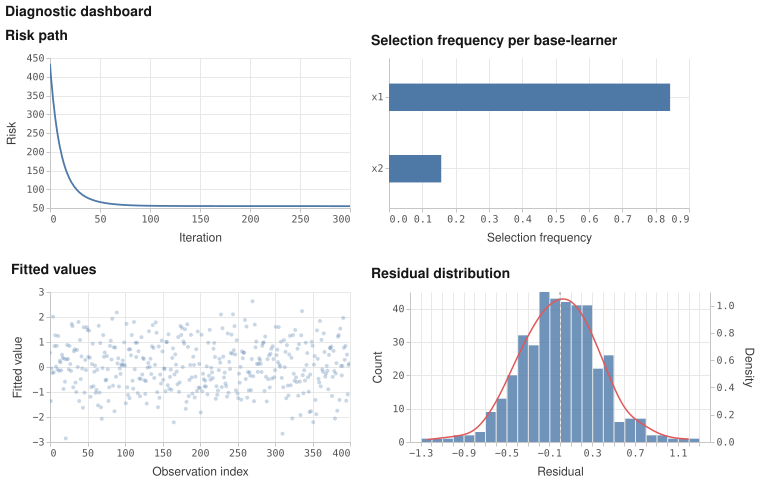

In [23]:
mb.plot.plot_diagnostics(fit)


## Summary of plot functions

All model-specific plots are available as methods on the fitted model object.
Functions that take non-model objects (`CvRiskResult`, `AicResult`, etc.) are
called as module-level functions.

| Call | What it shows |
|---|---|
| `fit.plot_risk()` | In-bag risk vs iteration |
| `glm.plot_coef_path()` or `glm.plot()` | Coefficient paths (GLM only) |
| `fit.plot_partial_effects()` or `fit.plot()` | Additive component curves (GAM only) |
| `mb.plot.plot_cvrisk(cvr)` | CV risk with fold traces and optimal mstop |
| `mb.plot.plot_aic(aic)` | AIC path with optimal mstop |
| `fit.plot_varimp()` | Variable importance bar chart |
| `fit.plot_residuals()` | Residuals vs fitted |
| `mb.plot.plot_confint(fit)` | CI bands (GAM) / forest plot (GLM) |
| `fit.plot_selected()` | Selection frequency per learner |
| `mb.plot.plot_lss(lss)` | LSS per-parameter partial effects |
| `mb.plot.plot_lss_risk(lss)` | LSS risk path |
| `lss.plot_density()` | Observed and average fitted response distribution |
| `lss.plot_centile_fan("x")` | Nested conditional centile bands |
| `lss.plot_deviance_profile(xvar="x")` | Binned joint deviance |
| `mb.plot.plot_multinomial(fit)` | Class probability curves (Multinomial) |
| `mb.plot.plot_lss_cvrisk(cvr)` | CV risk for LSS models |
| `mb.plot.plot_stabsel(ss)` | Selection probability bar chart |
| `mb.plot.plot_diagnostics(fit)` | 2×2 diagnostic dashboard |

### Model method shortcuts

| Method | Equivalent |
|---|---|
| `fit.plot_risk()` | `mb.plot.plot_risk(fit)` |
| `glm.plot()` | `glm.plot_coef_path()` |
| `fit.plot()` | `fit.plot_partial_effects()` |
| `fit.plot_varimp()` | `mb.plot.plot_varimp(fit)` |
| `fit.plot_selected()` | `mb.plot.plot_selected(fit)` |
| `fit.plot_residuals()` | `mb.plot.plot_residuals(fit)` |
| `lss.plot_density()` | `mb.plot.plot_distribution_density(lss)` |
| `lss.plot_centile_fan("x")` | `mb.plot.plot_centile_fan(lss, "x")` |
| `lss.plot_deviance_profile(xvar="x")` | `mb.plot.plot_deviance_profile(lss, xvar="x")` |
| `cvr.plot()` | `mb.plot.plot_cvrisk(cvr)` |

### Non-plot methods that return plottable data

| Method | Returns | Use with |
|---|---|---|
| `fit.aic()` | `AicResult(.aic, .mstop, .df)` | `mb.plot.plot_aic(fit.aic())` |
| `fit.varimp()` | `{reduction: ..., selfreq: ...}` | `fit.plot_varimp()` |
| `fit.confint(parm)` | `{lower, upper, level, ...}` | `mb.plot.plot_confint(fit, parm=...)` |
| `fit.residuals()` | array | `fit.plot_residuals()` |
| `mb.residual_frame(fit, kind=...)` | table | custom residual plots |
| `mb.calibration_frame(fit, xvar=...)` | table | observed-vs-fitted calibration plots |
| `mb.outlier_frame(fit)` | table | residual review |
| `fit.partial_effects()` | `{name: (x, y)}` | `fit.plot_partial_effects()` |
| `glm.coef_path()` | `{name: array}` | `glm.plot_coef_path()` |
| `lss.predict_all(output="auto")` | table | parameter plots |
| `lss.prediction_interval(level=...)` | table | interval coverage plots |
| `lss.residual_frame(kind="quantile")` | table | residual histograms / QQ plots |
| `lss.q_stats(xvar=...)` | table | binned distributional diagnostics |
| `lss.density_overlay_data()` | table | reconstruct or restyle the fitted-distribution overlay |
| `lss.centile_fan_data("x")` | table | inspect row identity and fitted centile values |
| `lss.deviance_profile(xvar="x")` | table | audit joint-deviance bin totals |

## Saving figures

All plot functions return Altair charts. To save a figure, use the chart's
`.save()` method:

In [24]:
fit.plot_risk().save("risk_path.png", scale_factor=2)
chart = fit.plot_risk()
chart.save("risk_path.pdf")

## Serialization

Models pickle like any Python object, so you can persist a fit and reload it
for prediction:

In [25]:
import pickle
blob = pickle.dumps(fit)
restored = pickle.loads(blob)
np.allclose(restored.predict(), fit.predict())

True

```{tip}
The pickle stores the fitted coefficients, the selection path, and enough of the
training metadata to predict on new data. It does not include the Rust
extension, so the loading environment must have a compatible `mboostrs`
installed.
```

### Result records: `to_dict`

The objects that analyses return — `CvRiskResult`, `StabSelResult`,
`AIPWResult`, `Deselection`, `GamRefit`, the effect and evaluation results and
the rest — share one export method, `to_dict(*, include_arrays=False)`. By
default it returns a record of plain Python numbers, strings, lists and dicts
that `json.dumps` accepts: summaries, settings and provenance, without the
per-observation or per-fold arrays. `include_arrays=True` adds those arrays as
lists. The flag must be passed by name; `to_dict(True)` raises `TypeError`.
Printing a result shows one line and never an array. A record is the form to
log, store next to a report, or pass to another program; the model itself is
saved with `save` or pickle.

In [26]:
import json

cv = fit.cvrisk(folds=mb.cv_weights(len(fit.fitted_), "kfold", 5, seed=1))
record = cv.to_dict()
full = cv.to_dict(include_arrays=True)
{"default keys": sorted(record),
 "keys added by include_arrays": sorted(set(full) - set(record)),
 "json length": len(json.dumps(record))}

{'default keys': ['aggregate',
  'boundary_warning',
  'data_fingerprint',
  'design',
  'fold_fingerprint',
  'fold_type',
  'folds',
  'grid',
  'held_out_fraction',
  'mstop_1se',
  'optimal_mstop',
  'preprocessing',
  'provenance',
  'standard_error'],
 'keys added by include_arrays': ['risk_matrix'],
 'json length': 14748}

## See also

- [](case_studies.ipynb) — worked examples that use these plot functions in real analyses.
- [](../methodology/worked_example) — the by-hand trace that the diagnostic plots visualize.